In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from sklearn.metrics import ConfusionMatrixDisplay

# Detect project root whether the notebook is opened from the root or notebooks/.
candidates = [Path.cwd(), Path.cwd().parent]
ROOT_DIR = next(
    (p.resolve() for p in candidates if (p / "src" / "dataset.py").exists()),
    Path.cwd().resolve()
)
if not (ROOT_DIR / "src" / "dataset.py").exists():
    raise FileNotFoundError(
        "Could not find src/dataset.py. Open Jupyter from the flower-image-classifier project."
    )

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

print("Project root:", ROOT_DIR)
print("PyTorch:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

Project root: C:\flower-image-classifier
PyTorch: 2.14.1+cpu
Device: cpu


Training images:   2568
Validation images: 551
Test images:       551
Total:             3670

Training class counts:


class_name
daisy         443
dandelion     628
roses         449
sunflowers    489
tulips        559
Name: count, dtype: int64

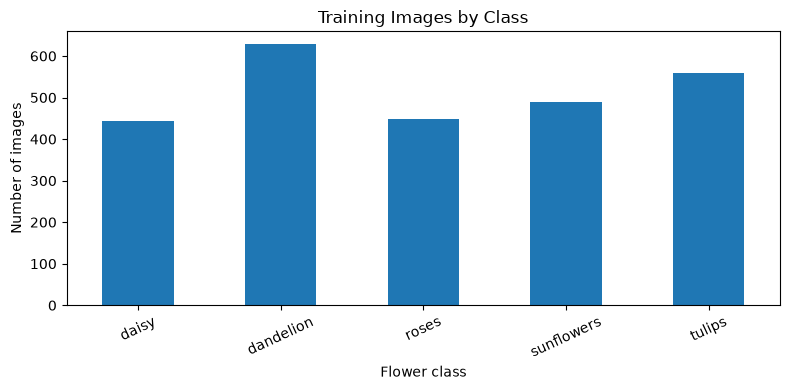

In [2]:
split_dir = ROOT_DIR / "reports" / "splits"
train_df = pd.read_csv(split_dir / "train.csv")
val_df = pd.read_csv(split_dir / "validation.csv")
test_df = pd.read_csv(split_dir / "test.csv")

print(f"Training images:   {len(train_df)}")
print(f"Validation images: {len(val_df)}")
print(f"Test images:       {len(test_df)}")
print(f"Total:             {len(train_df) + len(val_df) + len(test_df)}")

class_names = ["daisy", "dandelion", "roses", "sunflowers", "tulips"]
print("\nTraining class counts:")
display(train_df["class_name"].value_counts().reindex(class_names))

fig, ax = plt.subplots(figsize=(8, 4))
train_df["class_name"].value_counts().reindex(class_names).plot(kind="bar", ax=ax)
ax.set_title("Training Images by Class")
ax.set_xlabel("Flower class")
ax.set_ylabel("Number of images")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

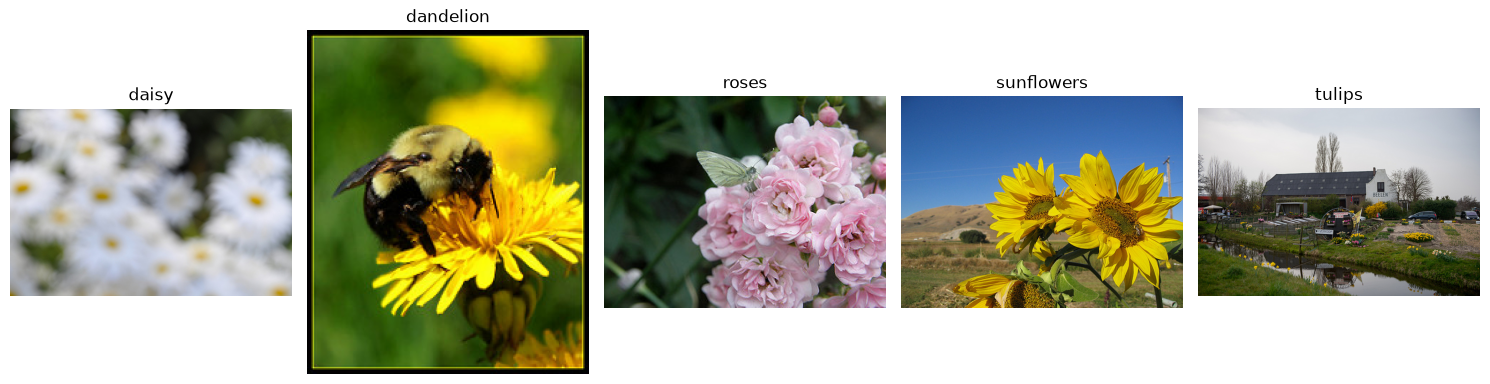

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for ax, class_name in zip(axes, class_names):
    row = train_df.loc[train_df["class_name"] == class_name].iloc[0]
    image_path = ROOT_DIR / row["path"]
    with Image.open(image_path) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(class_name)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
from src.dataset import create_dataloaders, train_transform, eval_transform

train_loader, val_loader, test_loader = create_dataloaders(ROOT_DIR)

images, labels = next(iter(train_loader))
print("Batch image shape:", tuple(images.shape))
print("Batch label shape:", tuple(labels.shape))
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Labels in batch:", labels.tolist())

Batch image shape: (16, 3, 224, 224)
Batch label shape: (16,)
Image dtype: torch.float32
Label dtype: torch.int64
Labels in batch: [0, 2, 2, 2, 3, 1, 0, 0, 4, 3, 0, 1, 4, 0, 4, 3]


In [5]:
from src.model import create_model, CLASS_NAMES

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = create_model(num_classes=len(CLASS_NAMES), freeze_features=True).to(device)
print(model.__class__.__name__)
print("Classes:", CLASS_NAMES)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable:,}")
print(f"Total parameters: {total:,}")

EfficientNet
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Trainable parameters: 6,405
Total parameters: 4,013,953


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.638369,0.802960,0.368526,0.892922
1,2,0.354068,0.890966,0.304475,0.911071
2,3,0.289014,0.910826,0.271624,0.920145


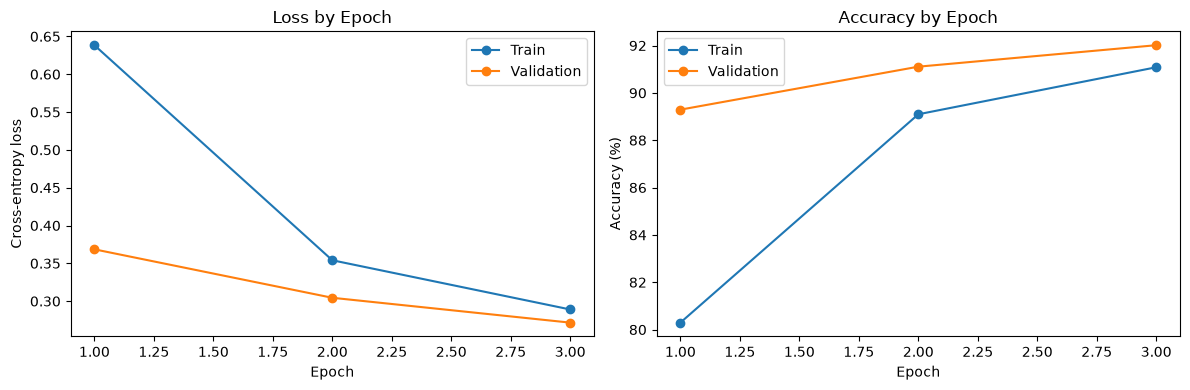

In [6]:
history_path = ROOT_DIR / "reports" / "training_history.json"
with open(history_path, "r", encoding="utf-8") as f:
    history = json.load(f)

history_df = pd.DataFrame(history)
display(history_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["train_accuracy"] * 100, marker="o", label="Train")
axes[1].plot(history_df["epoch"], history_df["val_accuracy"] * 100, marker="o", label="Validation")
axes[1].set_title("Accuracy by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [7]:
metrics_path = ROOT_DIR / "reports" / "test_metrics.json"
with open(metrics_path, "r", encoding="utf-8") as f:
    metrics = json.load(f)

summary = pd.DataFrame({
    "Metric": ["Test accuracy", "Macro precision", "Macro recall", "Macro F1-score"],
    "Value": [
        metrics["test_accuracy"],
        metrics["macro_precision"],
        metrics["macro_recall"],
        metrics["macro_f1"],
    ],
})
display(summary.style.format({"Value": "{:.4f}"}))
print(f"Test accuracy: {metrics['test_accuracy'] * 100:.2f}%")

,Metric,Value
0,Test accuracy,0.9183
1,Macro precision,0.9188
2,Macro recall,0.9174
3,Macro F1-score,0.9177


Test accuracy: 91.83%


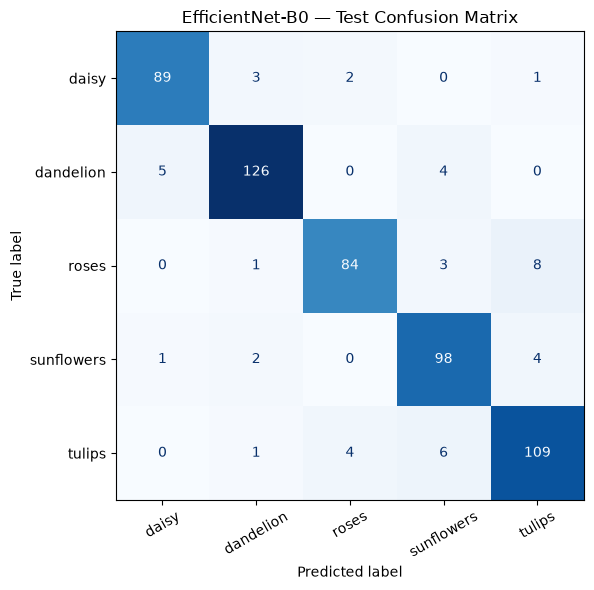

,precision,recall,f1-score,support
daisy,0.937,0.937,0.937,95.000
dandelion,0.947,0.933,0.940,135.000
roses,0.933,0.875,0.903,96.000
sunflowers,0.883,0.933,0.907,105.000
tulips,0.893,0.908,0.901,120.000
accuracy,0.918,0.918,0.918,0.918
macro avg,0.919,0.917,0.918,551.000
weighted avg,0.919,0.918,0.918,551.000


In [8]:
cm = np.array(metrics["confusion_matrix"])
fig, ax = plt.subplots(figsize=(7, 6))
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=metrics["class_names"])
display_cm.plot(ax=ax, cmap="Blues", xticks_rotation=30, values_format="d", colorbar=False)
ax.set_title("EfficientNet-B0 — Test Confusion Matrix")
plt.tight_layout()
plt.show()

report = pd.DataFrame(metrics["classification_report"]).T
display(report.round(3))

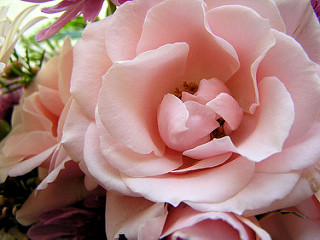

,Class,Softmax score (%)
0,roses,94.10
1,tulips,5.58
2,daisy,0.29


Predicted class: roses


In [9]:
from src.dataset import eval_transform

checkpoint_path = ROOT_DIR / "models" / "efficientnet_b0_best.pth"
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)

inference_model = create_model(
    num_classes=len(checkpoint["class_names"]),
    freeze_features=True
).to(device)
inference_model.load_state_dict(checkpoint["model_state_dict"])
inference_model.eval()

# Change this to any image path you want to classify.
IMAGE_PATH = ROOT_DIR / "data" / "raw" / "flower_photos" / "roses" / "12240303_80d87f77a3_n.jpg"

if not IMAGE_PATH.is_file():
    raise FileNotFoundError(f"Set IMAGE_PATH to an existing image: {IMAGE_PATH}")

with Image.open(IMAGE_PATH) as im:
    rgb_image = im.convert("RGB")
    display(rgb_image.copy())
    input_tensor = eval_transform(rgb_image).unsqueeze(0).to(device)

with torch.inference_mode():
    probabilities = torch.softmax(inference_model(input_tensor), dim=1)[0]

scores, indices = torch.topk(probabilities, k=min(3, len(checkpoint["class_names"])))
predictions = [
    {"Class": checkpoint["class_names"][idx.item()], "Softmax score (%)": round(score.item() * 100, 2)}
    for score, idx in zip(scores, indices)
]
display(pd.DataFrame(predictions))
print("Predicted class:", predictions[0]["Class"])